In [1]:
!nvidia-smi
import torch
print("GPU available:", torch.cuda.is_available())

Sat Oct 10 20:40:06 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
!ls /content

processed  sample_data	src


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
import torch, numpy as np, pandas as pd, transformers
from transformers import BertTokenizer, pipeline
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE", "| transformers", transformers.__version__)

train_df = pd.read_csv("/content/processed/train.csv")
val_df   = pd.read_csv("/content/processed/val.csv")
test_df  = pd.read_csv("/content/processed/test.csv")
print("rows:", len(train_df), len(val_df), len(test_df))

CHECKPOINT = "yiyanghkust/finbert-pretrain"
tokenizer = BertTokenizer.from_pretrained(CHECKPOINT, do_lower_case=True)   # <- the fix

# 1. Does it already "know" finance? Fill in the blank:
from transformers import BertForMaskedLM
mlm_model = BertForMaskedLM.from_pretrained(CHECKPOINT)       # <- the fix: say "it's a BERT"
fill = pipeline("fill-mask", model=mlm_model, tokenizer=tokenizer, device=0)
for r in fill("operating profit [MASK] to eur 13 million from eur 8 million ."):
    print(f"{r['token_str']:>12}  {r['score']:.3f}")

# 2. What the tokenizer does to one sentence
enc = tokenizer("Operating profit fell due to impairment charges .")
print(tokenizer.convert_ids_to_tokens(enc["input_ids"]))
print("input_ids     :", enc["input_ids"])
print("attention_mask:", enc["attention_mask"])

# 3. How long are our sentences in TOKENS? (decides max_length)
lengths = [len(tokenizer(s)["input_ids"]) for s in train_df["sentence_clean"]]
print("tokens 95th / 99th / max:", np.percentile(lengths, [95, 99]).round(), max(lengths))

GPU: Tesla T4 | transformers 5.18.0
rows: 2456 492 492


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  442MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: yiyanghkust/finbert-pretrain
Key                         | Status     |  | 
----------------------------+------------+--+-
cls.seq_relationship.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  442MB            

model.safetensors: downloading bytes:           |  0.00B            

   increased  0.264
    declined  0.186
    improved  0.133
        rose  0.122
   decreased  0.093
['[CLS]', 'operating', 'profit', 'fell', 'due', 'to', 'impairment', 'charges', '.', '[SEP]']
input_ids     : [3, 51, 358, 2444, 73, 9, 502, 631, 48, 4]
attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
tokens 95th / 99th / max: [57. 68.] 134


In [10]:
from transformers import BertForSequenceClassification, DataCollatorWithPadding
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, accuracy_score

LABELS = ["negative", "neutral", "positive"]
label_to_id = {l: i for i, l in enumerate(LABELS)}

class SentenceDataset(torch.utils.data.Dataset):
    def __init__(self, df):
        self.enc = tokenizer(df["sentence_clean"].tolist(), truncation=True, max_length=128)
        self.labels = df["label"].map(label_to_id).tolist()
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: torch.tensor(v[i]) for k, v in self.enc.items()}
        item["labels"] = torch.tensor(self.labels[i])
        return item

train_ds, val_ds, test_ds = SentenceDataset(train_df), SentenceDataset(val_df), SentenceDataset(test_df)
collator = DataCollatorWithPadding(tokenizer)    # pads each batch only to its longest sentence

y_train = np.array(train_ds.labels)
class_weights = torch.tensor(compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=y_train), dtype=torch.float)
print("class weights:", class_weights.round(decimals=2))

torch.manual_seed(42)
model = BertForSequenceClassification.from_pretrained(CHECKPOINT, num_labels=3)
print("Total params:", sum(p.numel() for p in model.parameters()))

class weights: tensor([2.7400, 0.5400, 1.3000])


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: yiyanghkust/finbert-pretrain
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpo

Total params: 109754115


In [11]:
import time
from transformers import Trainer, TrainingArguments, EarlyStoppingCallback
from sklearn.metrics import classification_report

class WeightedTrainer(Trainer):            # same Trainer, but with class weights in the loss
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs["labels"]
        outputs = model(**{k: v for k, v in inputs.items() if k != "labels"})
        loss_fn = torch.nn.CrossEntropyLoss(weight=class_weights.to(outputs.logits.device))
        loss = loss_fn(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {"macro_f1": f1_score(labels, preds, average="macro"), "accuracy": accuracy_score(labels, preds)}

args = TrainingArguments(
    output_dir="/content/finbert_runs",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    num_train_epochs=5,
    warmup_steps=77,                 # about 10% of 5 epochs x 154 steps
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=1,
    fp16=True,
    seed=42,
    report_to="none",
)

trainer = WeightedTrainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                          data_collator=collator, compute_metrics=compute_metrics,
                          callbacks=[EarlyStoppingCallback(early_stopping_patience=2)])

t0 = time.time()
trainer.train()
print("Training time (s):", round(time.time() - t0))

val_pred = trainer.predict(val_ds).predictions.argmax(axis=1)
print("Val Macro-F1:", round(f1_score(val_ds.labels, val_pred, average="macro"), 3))
print(classification_report(val_ds.labels, val_pred, target_names=LABELS, digits=3))

Epoch,Training Loss,Validation Loss,Macro F1,Accuracy
1,0.677895,0.339325,0.887049,0.918699
2,0.208366,0.230389,0.899282,0.922764
3,0.097291,0.306462,0.925537,0.947154
4,0.034427,0.386088,0.908737,0.932927
5,0.014971,0.329362,0.922540,0.943089


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training time (s): 98


Val Macro-F1: 0.926
              precision    recall  f1-score   support

    negative      0.898     0.883     0.891        60
     neutral      0.962     0.980     0.971       306
    positive      0.934     0.897     0.915       126

    accuracy                          0.947       492
   macro avg      0.931     0.920     0.926       492
weighted avg      0.947     0.947     0.947       492



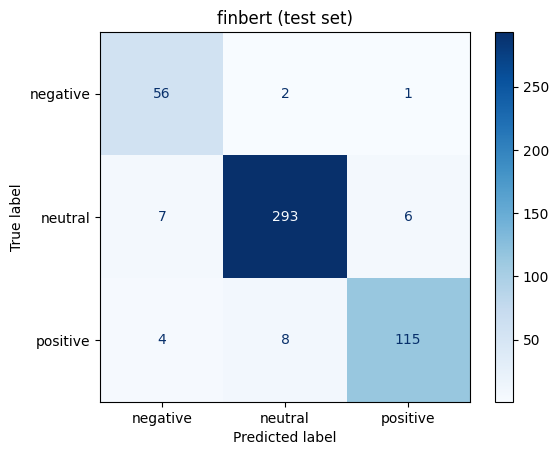

finbert on test: accuracy 0.9431 | Macro-F1 0.9249
              precision    recall  f1-score   support

    negative      0.836     0.949     0.889        59
     neutral      0.967     0.958     0.962       306
    positive      0.943     0.906     0.924       127

    accuracy                          0.943       492
   macro avg      0.915     0.937     0.925       492
weighted avg      0.945     0.943     0.943       492

finbert on test: accuracy 0.9431 | Macro-F1 0.9249


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

['config.json', 'model.safetensors', 'tokenizer_config.json', 'tokenizer.json', 'training_args.bin']


In [12]:
import sys, importlib, os, shutil
sys.path.append("/content")
import src.evaluate as ev
importlib.reload(ev)

# 1. Test ONCE with the frozen best model (epoch 3)
test_pred_ids = trainer.predict(test_ds).predictions.argmax(axis=1)
test_pred = [LABELS[i] for i in test_pred_ids]
metrics = ev.evaluate(test_df["label"].tolist(), test_pred, "finbert", "/content/results")
print("finbert on test: accuracy", round(metrics["accuracy"], 4), "| Macro-F1", round(metrics["macro_f1"], 4))

# 2. Save model + tokenizer + results to Google Drive
SAVE_DIR = "/content/drive/MyDrive/financial-news-intelligence"
trainer.save_model(f"{SAVE_DIR}/models/finbert")
tokenizer.save_pretrained(f"{SAVE_DIR}/models/finbert")
shutil.copytree("/content/results", f"{SAVE_DIR}/results", dirs_exist_ok=True)
print(os.listdir(f"{SAVE_DIR}/models/finbert"))